#1.IMPORT LIBRARY:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


#2.DATA UPLOADING:

In [ ]:
df = pd.read_csv("/content/3_diabetes_regression.csv")
print(df.head())

In [ ]:
X = df.drop(columns=["disease_progression"])
y = df["disease_progression"]

#3.TRAIN TEST SPLIT:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#4. STANDARD SCALER:

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#5. ANN SEQUENTIAL:

In [ ]:
model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dense(1)
])

#6.CREATED COMPILE:

In [ ]:
model.compile(optimizer="adam",
              loss="mean_squared_error",
              metrics=["mae"])

#7.MODEL FIT:

In [ ]:
history = model.fit(X_train_scaled, y_train, epochs=100, batch_size=16)
print("\n----- Diabets Regression ANN Model Training Complted Successfully!---")

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 29434.1328 - mae: 152.8475
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 28944.5742 - mae: 151.2640
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 28189.2070 - mae: 148.8681
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 26996.8438 - mae: 144.9562
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 25192.3027 - mae: 139.0169
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 22675.4688 - mae: 130.2467
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 19442.9316 - mae: 118.4514
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 15778.9619 - mae: 104.0451
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 12103.6924 - mae: 88.5455
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9042.2686 - mae: 74.5783
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6941.6069 - mae: 64.0787
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - los

#8.DIABETS REGRESSION GRAPH:

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


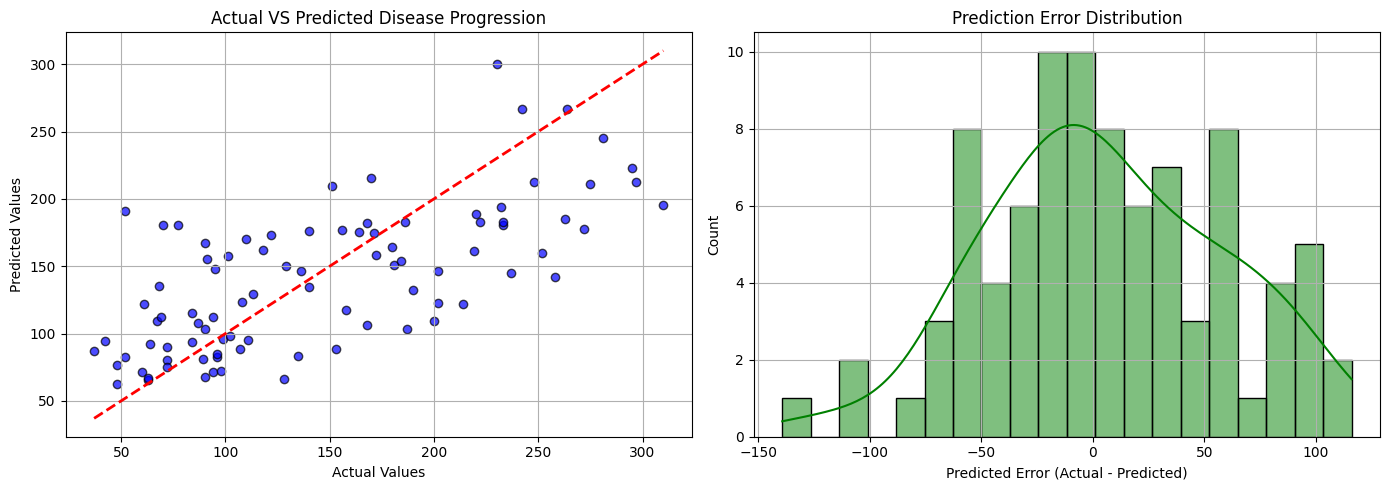

In [ ]:
y_pred = model.predict(X_test_scaled).flatten()

plt.figure(figsize=(14,5))

# ---- 1. Actual vs Predicted Scatter Plot ---
plt.subplot(1,2,1)
plt.scatter(y_test, y_pred, color="blue", alpha=0.7, edgecolors="k")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", lw=2)
plt.title("Actual VS Predicted Disease Progression")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.grid(True)

# --- 2. Prediction Error Distribution Plot ---
plt.subplot(1,2,2)
error = y_test - y_pred
sns.histplot(error, kde=True, color="green", bins=20)
plt.title("Prediction Error Distribution")
plt.xlabel("Predicted Error (Actual - Predicted)")
plt.ylabel("Count")
plt.grid(True)

plt.tight_layout()
plt.show()